<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>

# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 90.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 161.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 167.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [3]:
print("Shape", df.shape)
df.info()

Shape (65437, 114)
<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.6 MB


### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [4]:
## Identify missing values
df.isna().sum()

## Impute numerical columns with the median
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(df['ConvertedCompYearly'].median())
df['JobSat'] = df['JobSat'].fillna(df['JobSat'].median())

## Impute categorical columns with mode
df['RemoteWork'] = df['RemoteWork'].fillna(df['RemoteWork'].mode()[0])

## Verify
print(df[['ConvertedCompYearly', 'JobSat', 'RemoteWork']].isna().sum())

ConvertedCompYearly    0
JobSat                 0
RemoteWork             0
dtype: int64


### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [6]:
print("Employment:")
print(df['Employment'].value_counts().head(10))

print("\nJobSat:")
print(df['JobSat'].value_counts().sort_index())

print("\nYearsCodePro:")
print(df['YearsCodePro'].value_counts().head(10))

Employment:
Employment
Employed, full-time                                                         39041
Independent contractor, freelancer, or self-employed                         4846
Student, full-time                                                           4709
Employed, full-time;Independent contractor, freelancer, or self-employed     3557
Not employed, but looking for work                                           2341
Employed, part-time                                                          1266
Student, full-time;Employed, part-time                                       1115
Employed, full-time;Student, full-time                                        897
Employed, full-time;Student, part-time                                        839
Student, full-time;Not employed, but looking for work                         686
Name: count, dtype: int64

JobSat:
JobSat
0.0       311
1.0       276
2.0       772
3.0      1165
4.0      1130
5.0      1956
6.0      3751
7.0     42690
8.0

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


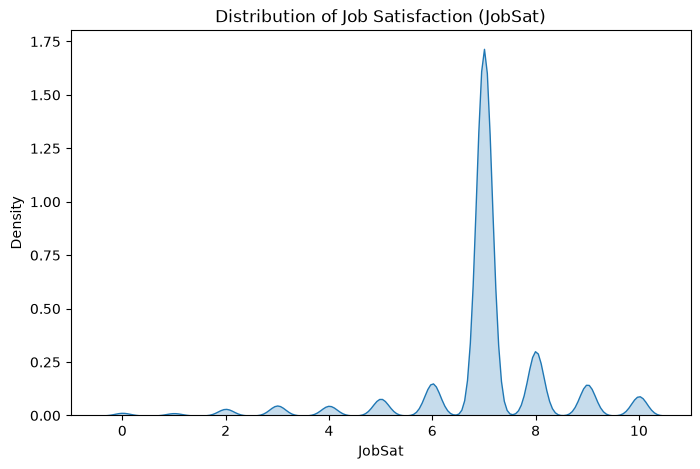

In [7]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='JobSat', fill=True)
plt.title('Distribution of Job Satisfaction (JobSat)')
plt.xlabel('JobSat')
plt.ylabel('Density')
plt.show()

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


                         Have Worked With  Want To Work With
LanguageHaveWorkedWith                                      
JavaScript                          37492              23774
HTML/CSS                            31816              20721
Python                              30719              25047
SQL                                 30682              22400
TypeScript                          23150              20239
Bash/Shell (all shells)             20412              13744
Java                                18239              10668
C#                                  16318              12921
C++                                 13827              10873
C                                   12184               8275


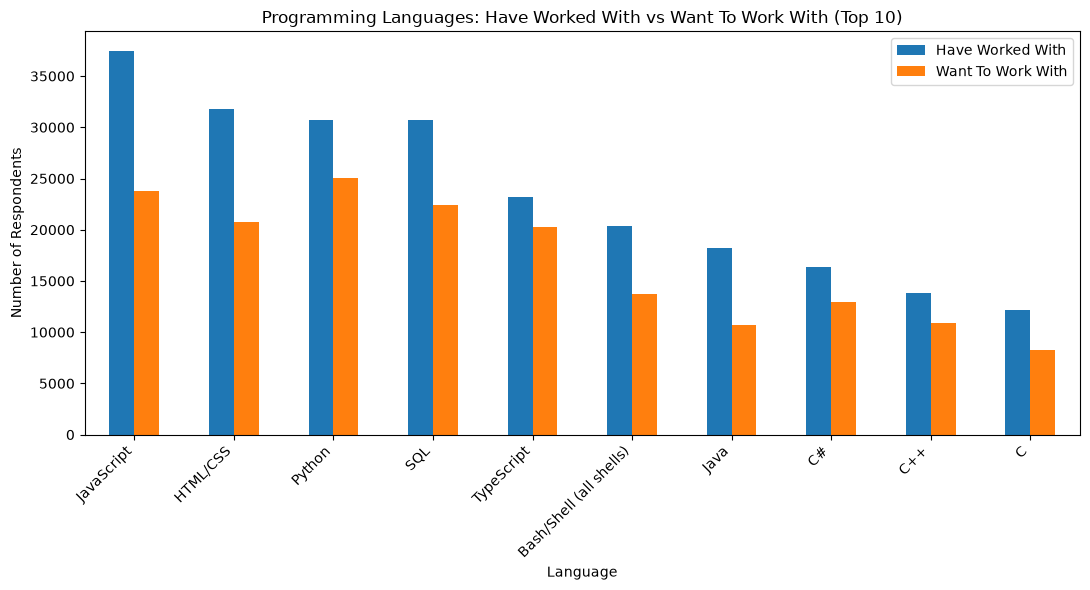

In [9]:
## Split and count languages in each column
worked = df['LanguageHaveWorkedWith'].dropna().str.split(';').explode().value_counts()
want = df['LanguageWantToWorkWith'].dropna().str.split(';').explode().value_counts()

## Compare the top 10 languagaes
top_langs = worked.head(10).index
compare = pd.DataFrame({
    'Have Worked With': worked[top_langs],
    'Want To Work With': want.reindex(top_langs)
})
print(compare)

## Grouped bar chart
compare.plot(kind='bar', figsize=(11, 6))
plt.title('Programming Languages: Have Worked With vs Want To Work With (Top 10)')
plt.xlabel('Language')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


RemoteWork                                          Hybrid (some remote, some in-person)  \
Country                                                                                    
Canada                                                                              46.1   
France                                                                              63.7   
Germany                                                                             62.6   
India                                                                               54.1   
Poland                                                                              44.7   
Ukraine                                                                             31.0   
United Kingdom of Great Britain and Northern Ir...                                  54.7   
United States of America                                                            43.8   

RemoteWork                                          In-person  Remote  
Country

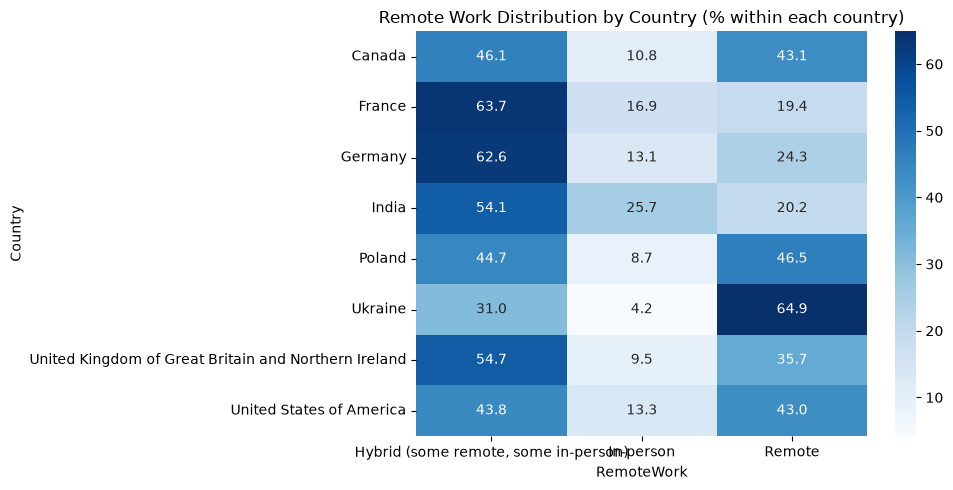

In [10]:
## Keep the top 8 countries by number of respondents
top_countries = df['Country'].value_counts().head(8).index
sub = df[df['Country'].isin(top_countries)]

## Percentage of each RemoteWork type within each country
ct = pd.crosstab(sub['Country'], sub['RemoteWork'], normalize='index') * 100
print(ct.round(1))

## Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(ct.round(1), annot=True, fmt='.1f', cmap='Blues')
plt.title('Remote Work Distribution by Country (% within each country)')
plt.xlabel('RemoteWork')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [12]:
## Make sure YearsCodePro is numeric
df['YearsCodePro'] = df['YearsCodePro'].replace({
    'Less than 1 year': 0,
    'More than 50 years': 50
})
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')

## Keep rows where both columns have values
data = df[['JobSat', 'YearsCodePro']].dropna()

## Correlation
print("Pearson:", data['JobSat'].corr(data['YearsCodePro'], method='pearson'))

Pearson: 0.07185818135381289


### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


EdLevel                                             Bachelor’s degree (B.A., B.S., B.Eng., etc.)  \
Employment                                                                                         
Employed, full-time                                                                        16806   
Employed, full-time;Independent contractor, fre...                                          1381   
Independent contractor, freelancer, or self-emp...                                          1592   
Not employed, but looking for work                                                           983   
Student, full-time                                                                           916   

EdLevel                                             Master’s degree (M.A., M.S., M.Eng., MBA, etc.)  \
Employment                                                                                            
Employed, full-time                                                                          

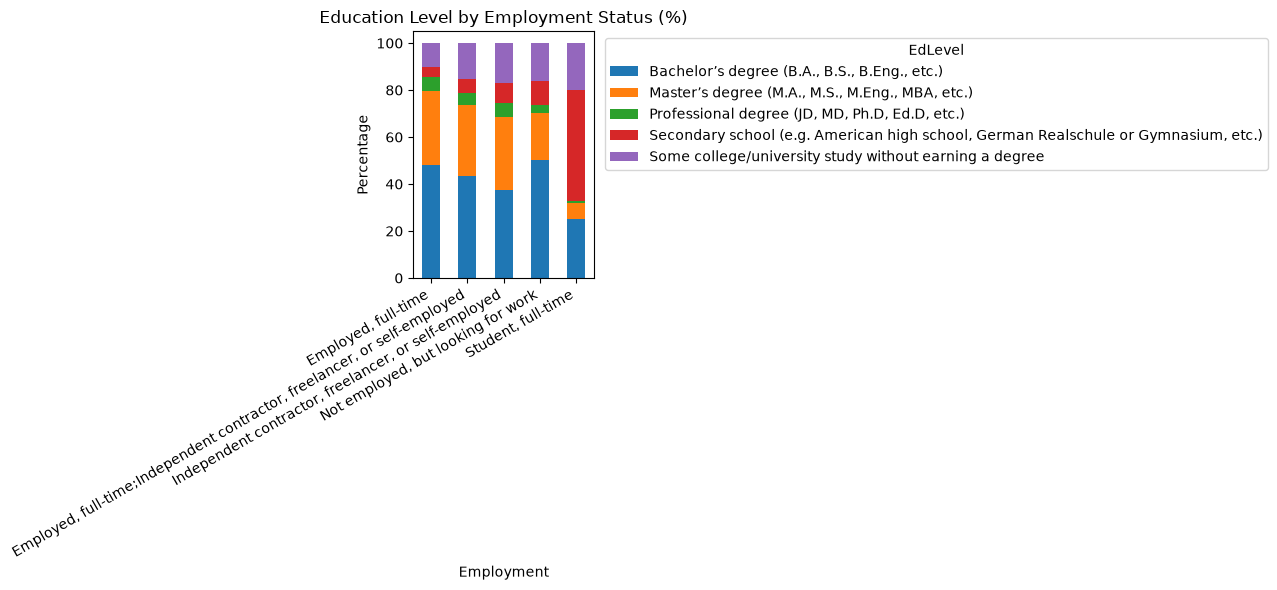

In [13]:
## Keep the top 5 categories of each column
top_emp = df['Employment'].value_counts().head(5).index
top_ed = df['EdLevel'].value_counts().head(5).index
sub = df[df['Employment'].isin(top_emp) & df['EdLevel'].isin(top_ed)]

## Cross-tabulation (counts)
ct = pd.crosstab(sub['Employment'], sub['EdLevel'])
print(ct)

## Percentage of each education level within each employment type
ct_pct = pd.crosstab(sub['Employment'], sub['EdLevel'], normalize='index') * 100
print(ct_pct.round(1))

## Stacked bar plot
ct_pct.plot(kind='bar', stacked=True, figsize=(11, 6))
plt.title('Education Level by Employment Status (%)')
plt.xlabel('Employment')
plt.ylabel('Percentage')
plt.xticks(rotation=30, ha='right')
plt.legend(title='EdLevel', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [14]:
## Export the cleaned dataset to a new CSV file
df.to_csv('cleaned_survey_data.csv', index=False)

print("Dataset saved. Shape:", df.shape)

Dataset saved. Shape: (65437, 114)


### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
